In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
%run /content/drive/MyDrive/Spam_vs_Ham/preprocessing_spam_ham_dataset.py

In [ ]:
import sys
sys.path.insert(0, '/content/drive/MyDrive/Spam_vs_Ham')

from preprocessing_spam_ham_dataset import (fetch_spam_data,
                                     load_email,
                                     get_email_structure,
                                     structure_counter,
                                     html_to_plain,
                                     email_to_text,
                                     EmailToWordCounterTransformer,
                                     WordCounterToVectorTransformer,)

In [ ]:
ham_dir,spam_dir=fetch_spam_data("20030228_hard_ham.tar.bz2","20030228_spam.tar.bz2","hard_ham","spam")

In [ ]:
len_checker={}

In [ ]:
from collections import Counter

In [ ]:
for f in ham_dir.iterdir():
  len_checker.setdefault(len(f.name),[]).append(1)

In [ ]:
for size,counting in len_checker.items():
  print(size,":",len(counting))

38 : 250
4 : 1


In [ ]:
Counter(len(file.name) for file in spam_dir.iterdir())

Counter({38: 500, 4: 1})

In [ ]:
ham_filenames=[f for f in sorted(ham_dir.iterdir()) if len(f.name)>20]
spam_filenames=[f for f in sorted(spam_dir.iterdir()) if len(f.name)>20]

In [ ]:
len(ham_filenames),len(spam_filenames) #spam are more

(250, 500)

In [ ]:
ham_emails=[load_email(file) for file in ham_filenames]
spam_emails=[load_email(file) for file in spam_filenames]

In [ ]:
print(ham_emails[0].get_content().strip()) #Ham content is getting similar to Spam content

======================== THE MOTLEY FOOL ========================
                        PERSONAL  FINANCE 
                    Wednesday, January 2, 2002 
										 
mkettler@home.com

IN THIS ISSUE

- ASK THE FOOL: Stop the Solicitation!
  http://www.fool.com/m.asp?i=562064

- YOUR MONEY: Resolutions You Can Keep
  http://www.fool.com/m.asp?i=562065

- SPOTLIGHT: Should All My Savings Be in the Market?
  http://www.fool.com/m.asp?i=562066
	
- COMMUNITY TIPS: Do (At Least) One Thing Differently
  http://www.fool.com/m.asp?i=562067


SPONSORED BY: Datek
Datek Online. Built to trade.
*Proprietary auto routing technology | *$9.99 commission 
for online equity trades | *60-second execution commitment.
Apply for a Datek Account Now!
http://www.lnksrv.com/m.asp?i=562068

ASK THE FOOL

Q. I'M TIRED OF GETTING SO MANY CREDIT CARD OFFERS IN THE MAIL. 
I ALREADY HAVE 
A CARD AND I DON'T WANT ANY MORE MAIL OFFERING ME NEW ONES. HOW 
CAN I STOP IT? 

A. There are three main credit bureaus in th

In [ ]:
print(spam_emails[1].get_content().strip()[:200])

1) Fight The Risk of Cancer!
http://www.adclick.ws/p.cfm?o=315&s=pk007

2) Slim Down - Guaranteed to lose 10-12 lbs in 30 days
http://www.adclick.ws/p.cfm?o=249&s=pk007

3) Get the Child Support You D


In [ ]:
result_spam=structure_counter(spam_emails)

In [ ]:
for key, value in result_spam.items():
    print(key, ":", value)

text/html : [0, 7, 9, 11, 13, 14, 24, 27, 28, 29, 34, 35, 36, 41, 43, 45, 48, 49, 51, 52, 54, 57, 58, 60, 65, 66, 82, 85, 87, 90, 93, 98, 100, 103, 106, 108, 113, 118, 120, 122, 124, 129, 132, 133, 135, 138, 142, 145, 146, 147, 148, 155, 160, 161, 163, 164, 165, 166, 167, 171, 172, 173, 174, 175, 176, 178, 180, 182, 187, 188, 189, 194, 195, 198, 199, 200, 201, 203, 204, 210, 211, 212, 214, 216, 220, 221, 230, 232, 243, 245, 250, 258, 265, 267, 273, 275, 280, 281, 283, 284, 285, 287, 289, 294, 295, 296, 299, 301, 303, 305, 309, 312, 313, 320, 321, 328, 330, 335, 344, 347, 349, 350, 352, 354, 356, 363, 367, 368, 373, 374, 375, 377, 379, 382, 384, 386, 390, 394, 395, 396, 397, 401, 404, 405, 406, 407, 411, 413, 415, 416, 417, 423, 424, 429, 432, 436, 440, 442, 447, 448, 449, 450, 452, 454, 455, 456, 460, 469, 470, 472, 473, 475, 476, 482, 486, 487, 490, 491, 492, 495, 496, 498, 499]
text/plain : [1, 2, 3, 4, 5, 6, 8, 10, 12, 15, 16, 17, 18, 19, 20, 25, 26, 30, 31, 32, 33, 39, 40, 42, 44, 

In [ ]:
[email.get_payload() for email in spam_emails[340].get_payload()]

[[<email.message.EmailMessage at 0x7cc82361f9d0>,
 '...\n0IjFADzo7V7vNYkAUAztPQDFEInvbY2AAAA7']

In [ ]:
print( spam_emails[15])

Return-Path: <des34newsa@hotmail.com>
Delivered-To: zzzz@localhost.spamassassin.taint.org
Received: from localhost (localhost [127.0.0.1])
	by phobos.labs.spamassassin.taint.org (Postfix) with ESMTP id 87DF44415B
	for <zzzz@localhost>; Fri, 23 Aug 2002 06:02:56 -0400 (EDT)
Received: from mail.webnote.net [193.120.211.219]
	by localhost with POP3 (fetchmail-5.9.0)
	for zzzz@localhost (single-drop); Fri, 23 Aug 2002 11:02:56 +0100 (IST)
Received: from tobe.co.kr ([211.219.114.162])
	by webnote.net (8.9.3/8.9.3) with ESMTP id GAA08628
	for <zzzz@spamassassin.taint.org>; Fri, 23 Aug 2002 06:38:03 +0100
From: des34newsa@hotmail.com
Received: from Spooler by tobe.co.kr (Mercury/32 v3.21c) ID MO000F96;
    23 Aug 02 14:56:22 +0900
Received:
 from spooler by tobe.co.kr (Mercury/32 v3.21c); 23 Aug 02 14:31:47 +0900
Received: from bigdog (63.186.16.221) by tobe.co.kr (Mercury/32 v3.21c) ID
 MG000F77;   23 Aug 02 14:31:34 +0900
To: 
Subject: Plans for cable
Date: Thu, 22 Aug 2002 23:41:26 -0500
X

In [ ]:
result_ham=structure_counter(ham_emails)

In [ ]:
for key,values in result_ham.items():
  print(key,':',values) #no pgp signature unlike easy ham.

text/plain : [0, 1, 2, 3, 4, 5, 8, 12, 13, 30, 41, 51, 65, 77, 87, 88, 103, 104, 124, 131, 135, 142, 144, 147, 151, 153, 154, 155, 156, 158, 160, 163, 164, 165, 170, 171, 173, 174, 176, 177, 180, 181, 183, 184, 185, 186, 187, 188, 189, 190, 191, 193, 194, 199, 204, 205, 207, 208, 210, 212, 214, 215, 216, 217, 218, 219, 224, 226, 227, 228, 229, 230, 231, 234, 235, 236, 237, 238, 243, 246, 247]
text/html : [6, 10, 11, 14, 15, 17, 18, 19, 21, 22, 23, 24, 25, 26, 27, 28, 29, 31, 33, 34, 35, 37, 39, 40, 42, 43, 44, 45, 46, 47, 48, 49, 50, 52, 53, 55, 56, 57, 58, 59, 60, 61, 64, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 78, 79, 80, 81, 82, 83, 84, 85, 86, 89, 90, 92, 93, 94, 95, 96, 97, 98, 99, 100, 101, 102, 105, 106, 107, 108, 109, 111, 112, 113, 114, 115, 116, 117, 118, 119, 120, 121, 122, 123, 125, 126, 127, 128, 129, 132, 133, 136, 137, 139, 140, 141, 143, 145, 146, 161, 162, 192, 200, 201, 206, 211, 213, 223]
multipart(text/plain,text/html) : [7, 9, 16, 20, 32, 36, 54, 62, 63, 91, 11

In [ ]:
print(ham_emails[13]) #URL links in ham emails are on rise!

Return-Path: <update@list.theregister.co.uk>
Received: from list.theregister.co.uk (theregister-sql2.hosted.netline.net.uk
 [213.40.196.63])	by dogma.slashnull.org (8.11.6/8.11.6) with ESMTP id
 g6A2h4T23295	for <qqqqqqqqqq-reg@spamassassin.taint.org>; Wed, 10 Jul 2002
 03:43:04 +0100
Received: from localhost ([127.0.0.1] helo=list.theregister.co.uk)
	by list.theregister.co.uk with smtp (Exim 3.31 #1)
	id 17S6q9-0005d6-0O
	for <qqqqqqqqqq-reg@spamassassin.taint.org>; Wed, 10 Jul 2002 03:04:25 +0100
Date: Wed, 10 Jul 2002 03:00:01 +0100
From: update@list.theregister.co.uk
Subject: Reg Headlines Wednesday July 10
To: Reg Subscribers <update@list.theregister.co.uk>
Precedence: list
X-Bulkmail: 2.05
Message-Id: <E17S6q9-0005d6-0O@list.theregister.co.uk>

Today's Headlines from The Register
-----------------------------------

    To unsubscribe from this daily news update, see the instructions at
    the end of this message.


  --------ADVERTISEMENT----------------------------------------

In [ ]:
counter_spam={key:len(values) for key,values in result_spam.items()}
for key, value in counter_spam.items():
  print(key,":",value)

text/html : 183
text/plain : 218
multipart(text/plain,application/octet-stream) : 1
multipart(text/html) : 20
multipart(text/plain,text/html) : 45
multipart(text/plain) : 19
multipart(text/html,text/plain) : 1
multipart(text/html,application/octet-stream) : 2
multipart(multipart(text/html)) : 5
multipart(text/plain,image/jpeg) : 3
multipart(multipart(text/html),application/octet-stream,image/jpeg) : 1
multipart(multipart(text/plain,text/html),image/gif) : 1
multipart/alternative : 1


In [ ]:
counter_ham={key:len(values) for key,values in result_ham.items()}
for key, value in counter_ham.items():
  print(key,":",value)

text/plain : 81
text/html : 118
multipart(text/plain,text/html) : 43
multipart(text/plain,image/bmp) : 1
multipart(multipart(text/plain,text/html)) : 1
multipart(text/plain,application/x-pkcs7-signature) : 1
multipart(text/html) : 2
multipart(text/plain,image/png,image/png) : 1
multipart(multipart(text/plain,text/html),image/gif,image/gif,image/gif,image/gif,image/gif,image/gif,image/gif,image/gif,image/gif,image/gif,image/gif,image/jpeg,image/gif,image/gif,image/gif,image/gif,image/gif,image/gif) : 1
multipart(text/plain,text/plain) : 1


In [ ]:
for header, value in spam_emails[100].items():
  print(header,':',value)

Return-Path : <FreeSoftware-5265v80@yahoo.com>
Delivered-To : zzzz@localhost.spamassassin.taint.org
Received : from localhost (localhost [127.0.0.1])	by phobos.labs.spamassassin.taint.org (Postfix) with ESMTP id BE46143F9B	for <zzzz@localhost>; Mon, 26 Aug 2002 16:37:20 -0400 (EDT)
Received : from mail.webnote.net [193.120.211.219]	by localhost with POP3 (fetchmail-5.9.0)	for zzzz@localhost (single-drop); Mon, 26 Aug 2002 21:37:20 +0100 (IST)
Received : from yahoo.com ([211.185.47.189])	by webnote.net (8.9.3/8.9.3) with SMTP id VAA27898	for <zzzz@spamassassin.taint.org>; Mon, 26 Aug 2002 21:39:06 +0100
Reply-To : Free Publishing Software <FreeSoftware-5265v80@yahoo.com>
Message-ID : <004b12e28d1a$4347d2b7$3ce68ab0@sgcrua>
From : Free Publishing Software <FreeSoftware-5265v80@yahoo.com>
To : zzzz@spamassassin.taint.org
Subject : Take your Marketing to the Next Level
Date : Mon, 26 Aug 2002 19:24:06 +0100
MiME-Version : 1.0
X-Priority : 3 (Normal)
X-MSMail-Priority : Normal
X-Mailer : Mi

In [ ]:
spam_emails[100]['Subject']

'Take your Marketing to the Next Level'

In [ ]:
import numpy as np
from sklearn.model_selection import train_test_split

In [ ]:
X=np.array(ham_emails+spam_emails,dtype=object)
y=np.array([0]*len(ham_emails)+[1]*len(spam_emails))

In [ ]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,stratify=y,random_state=42)

In [ ]:
html_spam_emails=[email for email in X_train[y_train==1] if get_email_structure(email)=='text/html']

In [ ]:
import urlextract
url_extractor=urlextract.URLExtract()

In [ ]:
X_few=X_train[:4]
X_few_transformed=EmailToWordCounterTransformer().fit_transform(X_few)

In [ ]:
[email.get_content() for email in X_few[3].get_payload()]

['<!DOCTYPE HTML PUBLIC "-//W3C//DTD HTML 4.01 Transitional//EN">\r\n<html>\r\n<head>\r\n<title>Adult Classified 2k2</title>\r\n<meta http-equiv="Content-Type" content="text/html; charset=iso-8859-1">\r\n</head>\r\n\r\n<body bgcolor="#FFFFFF" link="#CC9999" leftmargin="0" topmargin="0" marginwidth="0" marginheight="0">\r\n\r\n<center>\r\n  <br>\r\n  <table width="600" border="0" cellspacing="0" cellpadding="1">\r\n    <tr>\r\n      <td bgcolor="#990000"><table width="600" border="0" cellspacing="0" cellpadding="0">\r\n          <tr>\r\n            <td bgcolor="#FFFFFF">\r\n          \r\n          <div align="right"><img src="http://www.xxxmatch.net/logo.jpg" width="600" height="65"><br>\r\n          <b><font color="#CC0033" size="2" face="Geneva, Arial, Helvetica, sans-serif">--- The most comprehensive adult match making service<br>\r\n          <br>\r\n                    </font></b>\r\n</div></td>\r\n          </tr>\r\n          <tr>\r\n            <td bgcolor="#FFFFFF"><center>\r\n 

In [ ]:
print(X_train[0].get_content()[:100])

IN THIS ISSUE:

01. Readers write
02. Extension search
03. Dumb messages revisited
04. XP Tweak
05. 


In [ ]:
from scipy.sparse import csr_matrix

In [ ]:
X_few_transformed[-1]

array([Counter({'the': 43, 'a': 35, 'to': 32, 'and': 30, 'number': 29, 'you': 22, 'that': 19, 'in': 18, 'at': 14, 'of': 13, 'with': 12, 'is': 12, 'url': 11, 'we': 11, 'are': 10, 's': 9, 'on': 9, 'for': 9, 'window': 8, 'ad': 8, 'issu': 7, 'reader': 7, 'nnt': 7, 'your': 7, 'neat': 7, 'it': 7, 'by': 7, 'as': 7, 'if': 7, 'download': 7, 'dumb': 6, 'up': 6, 'get': 6, 'net': 6, 'trick': 6, 'site': 6, 'without': 6, 'be': 6, 'shortcut': 6, 'messag': 5, 'xp': 5, 'they': 5, 'subscrib': 5, 'pop': 5, 'can': 5, 'but': 5, 't': 5, 'our': 5, 'how': 5, 'anoth': 5, 'have': 5, 'or': 5, 'thi': 4, 'tweak': 4, 'tool': 4, 'button': 4, 'internet': 4, 'featur': 4, 'not': 4, 'will': 4, 'never': 4, 'wa': 4, 'inform': 4, 'comput': 4, 'other': 4, 'their': 4, 'do': 4, 'click': 4, 'oper': 4, 'need': 4, 'email': 4, 'all': 4, 'neatnettrick': 4, 'extens': 3, 'search': 3, 'hardwar': 3, 'hold': 3, 'freewar': 3, 'help': 3, 'next': 3, 'make': 3, 'more': 3, 'he': 3, 'onli': 3, 'those': 3, 'premium': 3, 'them': 3, 'there': 3,

In [ ]:
vocab_size=WordCounterToVectorTransformer(vocabulary_size=10)#an instance of class, this will contain necessary attributes.
RESULTS=vocab_size.fit_transform(X_few_transformed)

In [ ]:
RESULTS.toarray()#scipy.csr.matrix

array([[939,  43,  30,  32,  13,  29,  22,   7,  18,  11,  10],
       [242,   8,   7,  15,   9,  21,   9,  11,   4,   4,   3],
       [118,   6,   5,   2,   3,   0,   1,   0,   1,   0,   1],
       [123,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0]])

In [ ]:
print(X_few[0].get_content())

IN THIS ISSUE:

01. Readers write
02. Extension search
03. Dumb messages revisited
04. XP Tweak
05. Hardware Diagnostic Tool
06. Training Windows
07. Hold that button
08. Hagai's freeware
09. Online help

And Coming Next Week!

<><><><><><><><><><><><><><><><><><><><><><><><><><><><><><>
Make Internet Explorer Faster, More Capable, and Secure! 
NNT's reviewers called Secure IE great, easy-to-use,awesome,
impressive, a total "thumbs up"!  Read what they're raving 
about and get yours at http://www.secureie.com/p/nnt1/
<><><><><><><><><><><><><><><><><><><><><><><><><><><><><><>

01. READERS WRITE.  A Wisconsin subscriber wrote to express his displeasure 
with the links contained in Neat Net Tricks.  It seems he is bothered by 
the frequent pop-up ads and he felt that only those sites without the ads 
should be featured in NNT, particularly in the Premium issue. We replied 
that pop-ups can be annoying but, while not defending them, we must realize 
that they are a form of marketing in w

In [ ]:
vocab_size.vocabulary_

{'the': 1,
 'and': 2,
 'to': 3,
 'of': 4,
 'number': 5,
 'you': 6,
 'your': 7,
 'in': 8,
 'we': 9,
 'are': 10}

In [ ]:
vocab_size.count_of_words

[('the', 24),
 ('and', 22),
 ('to', 22),
 ('of', 22),
 ('number', 20),
 ('you', 20),
 ('your', 17),
 ('in', 15),
 ('we', 14),
 ('are', 14)]

In [ ]:
X_100=X_train[-100:]
X_100_transformed=EmailToWordCounterTransformer().fit_transform(X_100)

In [ ]:
vocab_size=WordCounterToVectorTransformer(vocabulary_size=15)
X_100_vector=vocab_size.fit_transform(X_100_transformed)

In [ ]:
X_100_vector.toarray()[:10].tolist()

[[472, 80, 10, 13, 11, 12, 5, 9, 9, 2, 13, 4, 1, 6, 1, 6],
 [740, 45, 20, 39, 10, 13, 0, 14, 10, 10, 11, 2, 6, 6, 0, 9],
 [18, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
 [118, 2, 4, 2, 4, 6, 6, 2, 2, 0, 0, 0, 3, 4, 1, 0],
 [1160, 22, 43, 71, 28, 33, 16, 25, 24, 21, 16, 18, 8, 18, 2, 25],
 [118, 2, 10, 1, 4, 4, 3, 3, 0, 0, 0, 2, 3, 2, 4, 0],
 [250, 4, 13, 11, 8, 9, 7, 7, 6, 4, 1, 3, 4, 1, 6, 1],
 [85, 11, 6, 4, 2, 2, 3, 0, 4, 2, 4, 4, 3, 1, 0, 1],
 [374, 12, 11, 9, 8, 17, 13, 4, 5, 3, 2, 17, 11, 3, 5, 3],
 [234, 10, 7, 17, 11, 7, 10, 6, 4, 3, 5, 4, 0, 3, 0, 2]]

In [ ]:
print(url_extractor.find_urls(X_train[-97].get_content()))

['http://ter.netblah.com:27000', 'http://ter.netblah.com:27000', 'http://ter.netblah.com:27000']


In [ ]:
vocab_size.count_of_words

[('number', 670),
 ('to', 608),
 ('the', 541),
 ('and', 459),
 ('a', 458),
 ('you', 421),
 ('of', 404),
 ('for', 395),
 ('in', 352),
 ('s', 315),
 ('your', 312),
 ('url', 311),
 ('is', 311),
 ('thi', 292),
 ('it', 283)]

In [ ]:
from sklearn.pipeline import Pipeline,make_pipeline

In [ ]:
preprocess_pipeline=Pipeline([
    ("email_to_word_count",EmailToWordCounterTransformer()),
    ("word_count_to_vector",WordCounterToVectorTransformer())
])

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score

In [ ]:
log_clf=LogisticRegression(max_iter=1000,random_state=42)
log_pipeline=make_pipeline(preprocess_pipeline,log_clf)

In [ ]:
score=cross_val_score(log_pipeline,X_train,y_train,cv=3)
score.mean()

np.float64(0.93)

In [ ]:
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score,classification_report,ConfusionMatrixDisplay

In [ ]:
log_pipeline.fit(X_train,y_train)
y_pred=log_pipeline.predict(X_test)

In [ ]:
print(f"Accuracy : {accuracy_score(y_test,y_pred):.3%}")
print(f"Precision : {precision_score(y_test,y_pred):.3%}")
print(f"Recall : {recall_score(y_test,y_pred):.3%}")
print(f"F-1 score : {f1_score(y_test,y_pred):.3%}")
print("Classification Report:")
print(classification_report(y_test,y_pred,target_names=['Ham','Spam']))

Accuracy : 92.000%
Precision : 90.000%
Recall : 99.000%
F-1 score : 94.286%
Classification Report:
              precision    recall  f1-score   support

         Ham       0.97      0.78      0.87        50
        Spam       0.90      0.99      0.94       100

    accuracy                           0.92       150
   macro avg       0.94      0.89      0.90       150
weighted avg       0.93      0.92      0.92       150



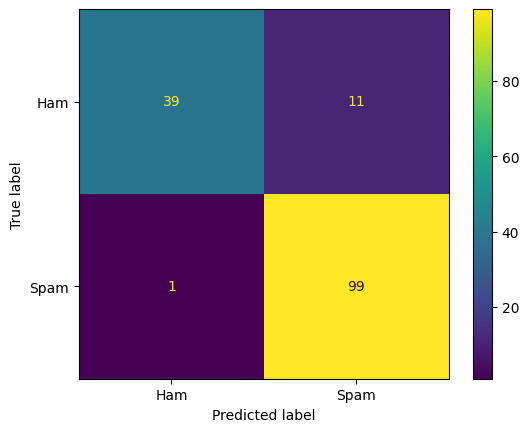

In [ ]:
ConfusionMatrixDisplay.from_predictions(y_test,y_pred,display_labels=['Ham','Spam'])
plt.show()

In [ ]:
from sklearn.ensemble import RandomForestClassifier

In [ ]:
random_forest=RandomForestClassifier()
forest_pipeline=make_pipeline(preprocess_pipeline,random_forest)

In [ ]:
forest_pipeline.fit(X_train,y_train)

Pipeline(steps=[('pipeline',
                 Pipeline(steps=[('email_to_word_count',
                                  EmailToWordCounterTransformer()),
                                 ('word_count_to_vector',
                                  WordCounterToVectorTransformer())])),
                ('randomforestclassifier', RandomForestClassifier())])

In [ ]:
y_pred=forest_pipeline.predict(X_test)

In [ ]:
print(f"Accuracy : {accuracy_score(y_test,y_pred):.3%}")
print(f"Precision : {precision_score(y_test,y_pred):.3%}")
print(f"Recall : {recall_score(y_test,y_pred):.3%}")
print(f"F-1 score : {f1_score(y_test,y_pred):.3%}")
print("Classification Report:")
print(classification_report(y_test,y_pred,target_names=['Ham','Spam']))

Accuracy : 90.667%
Precision : 89.091%
Recall : 98.000%
F-1 score : 93.333%
Classification Report:
              precision    recall  f1-score   support

         Ham       0.95      0.76      0.84        50
        Spam       0.89      0.98      0.93       100

    accuracy                           0.91       150
   macro avg       0.92      0.87      0.89       150
weighted avg       0.91      0.91      0.90       150



In [ ]:
forest_pipeline[-1].get_params() #time to do hyperparameter tuning

{'bootstrap': True,
 'ccp_alpha': 0.0,
 'class_weight': None,
 'criterion': 'gini',
 'max_depth': None,
 'max_features': 'sqrt',
 'max_leaf_nodes': None,
 'max_samples': None,
 'min_impurity_decrease': 0.0,
 'min_samples_leaf': 1,
 'min_samples_split': 2,
 'min_weight_fraction_leaf': 0.0,
 'monotonic_cst': None,
 'n_estimators': 100,
 'n_jobs': None,
 'oob_score': False,
 'random_state': None,
 'verbose': 0,
 'warm_start': False}

In [ ]:
from sklearn.model_selection import GridSearchCV

In [ ]:
params={"randomforestclassifier__n_estimators":[100,200],
         "randomforestclassifier__max_features": ["sqrt", 0.5],
        "randomforestclassifier__min_samples_leaf":[1,3,5],
        "randomforestclassifier__min_samples_split":[2,4]}

In [ ]:
gridsearch=GridSearchCV(forest_pipeline,params,cv=3,scoring='f1')

In [66]:
gridsearch.fit(X_train,y_train)

GridSearchCV(cv=3,
             estimator=Pipeline(steps=[('pipeline',
                                        Pipeline(steps=[('email_to_word_count',
                                                         EmailToWordCounterTransformer()),
                                                        ('word_count_to_vector',
                                                         WordCounterToVectorTransformer())])),
                                       ('randomforestclassifier',
                                        RandomForestClassifier())]),
             param_grid={'randomforestclassifier__max_features': ['sqrt', 0.5],
                         'randomforestclassifier__min_samples_leaf': [1, 3, 5],
                         'randomforestclassifier__min_samples_split': [2, 4],
                         'randomforestclassifier__n_estimators': [100, 200]},
             scoring='f1')

In [67]:
gridsearch.best_params_

{'randomforestclassifier__max_features': 'sqrt',
 'randomforestclassifier__min_samples_leaf': 1,
 'randomforestclassifier__min_samples_split': 2,
 'randomforestclassifier__n_estimators': 100}

In [68]:
final_model=gridsearch.best_estimator_

In [76]:
final_model['randomforestclassifier'].feature_importances_.shape

(1001,)

In [77]:
final_model.fit(X_train,y_train)

Pipeline(steps=[('pipeline',
                 Pipeline(steps=[('email_to_word_count',
                                  EmailToWordCounterTransformer()),
                                 ('word_count_to_vector',
                                  WordCounterToVectorTransformer())])),
                ('randomforestclassifier', RandomForestClassifier())])

In [78]:
y_pred=final_model.predict(X_test)

In [79]:
print(f"Accuracy : {accuracy_score(y_test,y_pred):.3%}")
print(f"Precision : {precision_score(y_test,y_pred):.3%}")
print(f"Recall : {recall_score(y_test,y_pred):.3%}")
print(f"F-1 score : {f1_score(y_test,y_pred):.3%}")
print("Classification Report:")
print(classification_report(y_test,y_pred,target_names=['Ham','Spam']))

Accuracy : 90.000%
Precision : 88.288%
Recall : 98.000%
F-1 score : 92.891%
Classification Report:
              precision    recall  f1-score   support

         Ham       0.95      0.74      0.83        50
        Spam       0.88      0.98      0.93       100

    accuracy                           0.90       150
   macro avg       0.92      0.86      0.88       150
weighted avg       0.90      0.90      0.90       150



Even with hyperparameter tuning my best params were as same as non tuned parameters

In [80]:
from sklearn.naive_bayes import MultinomialNB

In [82]:
clf_MNB=MultinomialNB()

In [83]:
mnb_pipeline=make_pipeline(preprocess_pipeline,clf_MNB)

In [84]:
mnb_pipeline.fit(X_train,y_train)

Pipeline(steps=[('pipeline',
                 Pipeline(steps=[('email_to_word_count',
                                  EmailToWordCounterTransformer()),
                                 ('word_count_to_vector',
                                  WordCounterToVectorTransformer())])),
                ('multinomialnb', MultinomialNB())])

In [86]:
y_pred=mnb_pipeline.predict(X_test)

In [90]:
y_pred[:10]

array([1, 0, 1, 1, 1, 1, 0, 0, 0, 0])

In [91]:
print(f"Accuracy : {accuracy_score(y_test,y_pred):.3%}")
print(f"Precision : {precision_score(y_test,y_pred):.3%}")
print(f"Recall : {recall_score(y_test,y_pred):.3%}")
print(f"F-1 score : {f1_score(y_test,y_pred):.3%}")
print("Classification Report:")
print(classification_report(y_test,y_pred,target_names=['Ham','Spam']))

Accuracy : 86.667%
Precision : 95.455%
Recall : 84.000%
F-1 score : 89.362%
Classification Report:
              precision    recall  f1-score   support

         Ham       0.74      0.92      0.82        50
        Spam       0.95      0.84      0.89       100

    accuracy                           0.87       150
   macro avg       0.85      0.88      0.86       150
weighted avg       0.88      0.87      0.87       150



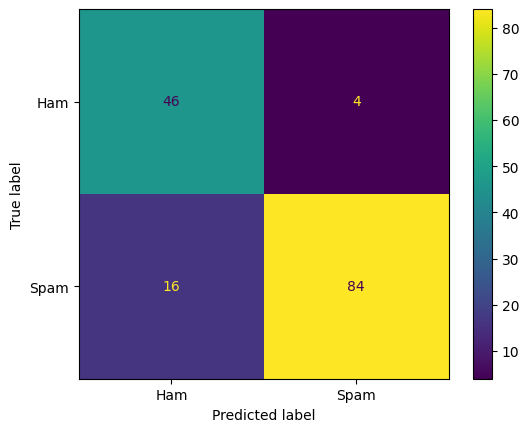

In [92]:
ConfusionMatrixDisplay.from_predictions(y_test,y_pred,display_labels=['Ham','Spam'])
plt.show()

In [117]:
from sklearn.svm import LinearSVC

In [118]:
svc=LinearSVC()
svc_pipeline=make_pipeline(preprocess_pipeline,svc)

In [119]:
svc_pipeline.fit(X_train,y_train)

/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


Pipeline(steps=[('pipeline',
                 Pipeline(steps=[('email_to_word_count',
                                  EmailToWordCounterTransformer()),
                                 ('word_count_to_vector',
                                  WordCounterToVectorTransformer())])),
                ('linearsvc', LinearSVC())])

In [120]:
y_pred=svc_pipeline.predict(X_test)

In [121]:
print(f"Accuracy : {accuracy_score(y_test,y_pred):.3%}")
print(f"Precision : {precision_score(y_test,y_pred):.3%}")
print(f"Recall : {recall_score(y_test,y_pred):.3%}")
print(f"F-1 score : {f1_score(y_test,y_pred):.3%}")
print("Classification Report:")
print(classification_report(y_test,y_pred,target_names=['Ham','Spam']))

Accuracy : 91.333%
Precision : 89.189%
Recall : 99.000%
F-1 score : 93.839%
Classification Report:
              precision    recall  f1-score   support

         Ham       0.97      0.76      0.85        50
        Spam       0.89      0.99      0.94       100

    accuracy                           0.91       150
   macro avg       0.93      0.88      0.90       150
weighted avg       0.92      0.91      0.91       150



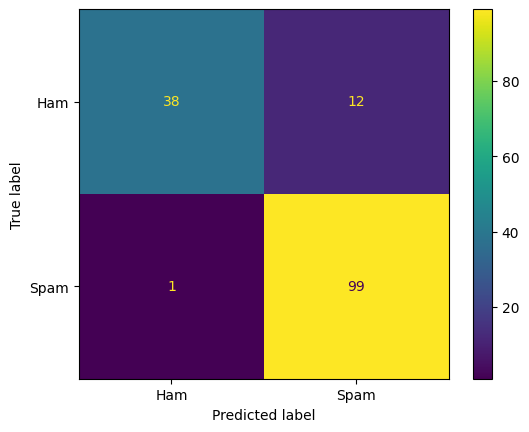

In [122]:
ConfusionMatrixDisplay.from_predictions(y_test,y_pred,display_labels=['Ham','Spam'])
plt.show()

In [115]:
import xgboost as xgb

xgb_clf = xgb.XGBClassifier(n_estimators=100,max_depth=6,learning_rate=0.1,objective="binary:logistic",
                            eval_metric="logloss",random_state=42,n_jobs=-1)

xgb_pipeline = make_pipeline(preprocess_pipeline,xgb_clf)

xgb_pipeline.fit(X_train, y_train)

y_pred = xgb_pipeline.predict(X_test)


In [114]:
print(f"Accuracy : {accuracy_score(y_test,y_pred):.3%}")
print(f"Precision : {precision_score(y_test,y_pred):.3%}")
print(f"Recall : {recall_score(y_test,y_pred):.3%}")
print(f"F-1 score : {f1_score(y_test,y_pred):.3%}")
print("Classification Report:")
print(classification_report(y_test,y_pred,target_names=['Ham','Spam']))

Accuracy : 91.333%
Precision : 88.496%
Recall : 100.000%
F-1 score : 93.897%
Classification Report:
              precision    recall  f1-score   support

         Ham       1.00      0.74      0.85        50
        Spam       0.88      1.00      0.94       100

    accuracy                           0.91       150
   macro avg       0.94      0.87      0.89       150
weighted avg       0.92      0.91      0.91       150



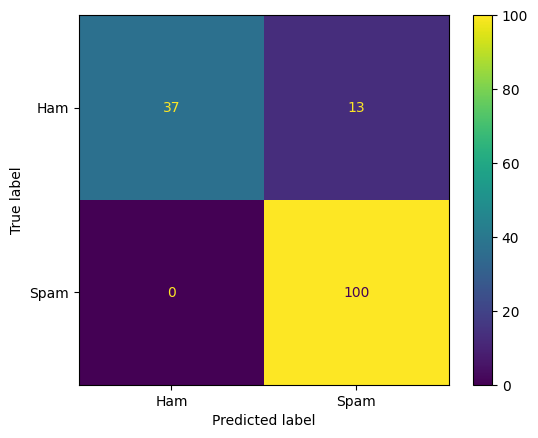

In [116]:
ConfusionMatrixDisplay.from_predictions(y_test,y_pred,display_labels=['Ham','Spam'])
plt.show()